# 03 · Phân cụm khách hàng bằng GMM

Phần của Tuananh dùng Gaussian Mixture Model trên tập development sau tiền xử lý. Pipeline điền giá trị thiếu, chuẩn hóa các cột số và mã hóa category được fit trên đặc trưng của development. Response dùng để mô tả và trực quan hóa các cụm sau khi chọn mô hình.

Thử 2–8 thành phần với ma trận hiệp phương sai đường chéo, 5 lần khởi tạo, tối đa 500 bước EM, `reg_covar=1e-5` và seed 42. Chọn BIC nhỏ nhất trong các mô hình hội tụ và có ít nhất hai cụm được gán mẫu. Mỗi ứng viên cũng được đánh giá bằng Silhouette Euclidean trên toàn bộ không gian đặc trưng đã mã hóa.

GMM mô hình hóa phân phối bằng hỗn hợp Gaussian. Với các cột one-hot và biến đếm rời rạc, giả định này mang tính xấp xỉ. Hiệp phương sai đường chéo giả định các đặc trưng độc lập có điều kiện trong mỗi thành phần.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

root = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "src" / "clustering.py").is_file()
)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src import config
from src.clustering import evaluate_gmm

sns.set_theme(style="whitegrid")
figures = config.FIGURES_CLUSTERING_DIR
figures.mkdir(parents=True, exist_ok=True)
config.TABLES_DIR.mkdir(parents=True, exist_ok=True)
selection, profiles, visual = evaluate_gmm()
selection.to_csv(config.TABLES_DIR / "gmm_model_selection.csv", index=False)
profiles.to_csv(config.TABLES_DIR / "gmm_cluster_profiles.csv", index=False)
chosen = selection.loc[selection["selected"]].iloc[0]
print(
    f"{len(visual):,} mẫu, {chosen['n_features']} đặc trưng. "
    f"Chọn {chosen['n_components']} thành phần, Silhouette={chosen['silhouette']:.3f}."
)

1,788 mẫu, 37 đặc trưng. Chọn 8 thành phần, Silhouette=0.109.


,n_components,n_clusters,converged,iterations,bic,aic,silhouette,selected
0,2,2,True,7,73994.811,73176.972,0.262,False
1,3,3,True,7,36809.886,35580.383,0.202,False
2,4,4,True,23,519.339,-1121.828,0.150,False
3,5,5,True,18,-11555.977,-13608.808,0.151,False
4,6,6,True,49,-50382.924,-52847.419,0.133,False
5,7,7,True,9,-42763.015,-45639.174,0.133,False
6,8,8,True,38,-53872.618,-57160.441,0.109,True


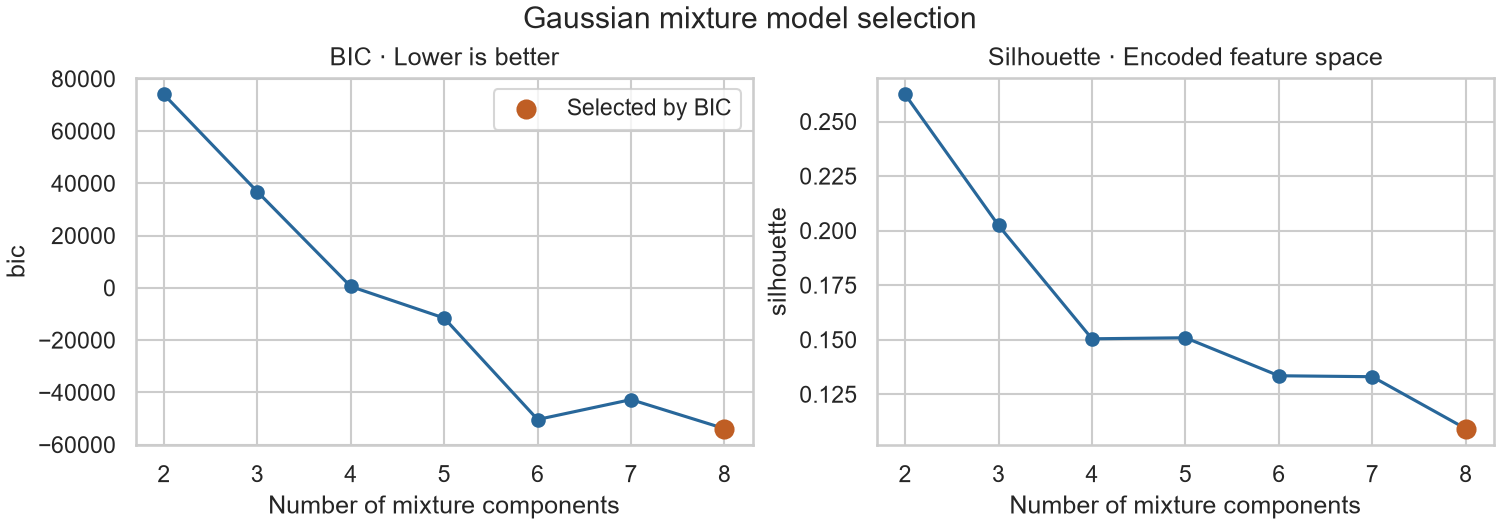

In [2]:
display(selection[[
    "n_components", "n_clusters", "converged", "iterations", "bic", "aic",
    "silhouette", "selected"
]].round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for ax, metric, title in zip(
    axes, ("bic", "silhouette"),
    ("BIC · Lower is better", "Silhouette · Encoded feature space"),
):
    ax.plot(selection["n_components"], selection[metric], marker="o", color="#28679A")
    ax.scatter(chosen["n_components"], chosen[metric], color="#BF5E24", s=75, zorder=3, label="Selected by BIC")
    ax.set(title=title, xlabel="Number of mixture components", ylabel=metric)
    ax.set_xticks(selection["n_components"])
axes[0].legend()
fig.suptitle("Gaussian mixture model selection")
fig.savefig(figures / "gmm_model_selection.png", dpi=config.FIGURE_DPI)
plt.show()
plt.close(fig)

## Hồ sơ khách hàng và hưởng ứng theo cụm

Các trung vị Income, Age, tổng chi tiêu, số lần mua, Recency và số con được tính trong đơn vị gốc. `response_lift` bằng tỷ lệ hưởng ứng của cụm chia cho tỷ lệ chung trên development. Nhãn Response chỉ được đối chiếu sau khi GMM đã gán cụm.

,cluster,customers,responders,response_rate,median_income,median_age,median_spending,median_purchases,median_recency,median_children,customer_fraction,response_lift
0,0,571,36,0.063,36535.0,42.0,65.0,6.0,50.0,1.0,0.319,0.422
1,1,124,20,0.161,25833.0,36.0,53.0,4.5,49.0,1.0,0.069,1.080
2,2,199,84,0.422,76995.0,45.0,1381.0,18.0,52.0,0.0,0.111,2.827
3,3,68,30,0.441,49912.0,45.0,657.0,16.0,34.5,1.0,0.038,2.954
4,4,270,49,0.181,73455.0,47.0,1232.5,18.0,53.5,0.0,0.151,1.215
5,5,423,27,0.064,59934.0,48.0,704.0,17.0,50.0,1.0,0.237,0.427
6,6,112,6,0.054,26490.0,44.5,84.5,6.0,53.5,0.0,0.063,0.359
7,7,21,15,0.714,65169.0,46.0,1199.0,18.0,44.0,0.0,0.012,4.783


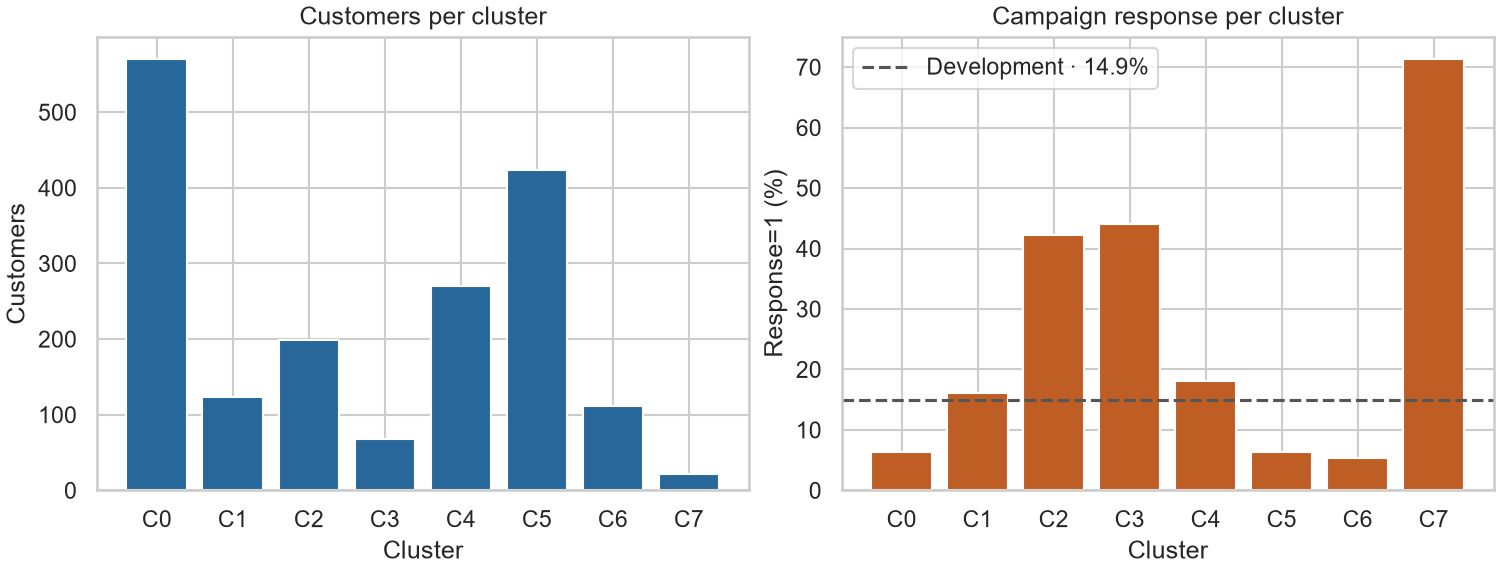

In [3]:
display(profiles.round(3))
names = [f"C{label}" for label in profiles["cluster"]]
baseline = visual["Response"].mean()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
axes[0].bar(names, profiles["customers"], color="#28679A")
axes[0].set(title="Customers per cluster", xlabel="Cluster", ylabel="Customers")
axes[1].bar(names, profiles["response_rate"] * 100, color="#BF5E24")
axes[1].axhline(baseline * 100, color="#555555", linestyle="--", label=f"Development · {baseline:.1%}")
axes[1].set(title="Campaign response per cluster", xlabel="Cluster", ylabel="Response=1 (%)")
axes[1].legend()
fig.savefig(figures / "gmm_cluster_response.png", dpi=config.FIGURE_DPI)
plt.show()
plt.close(fig)

## Trực quan hóa cụm và nhãn

PCA 2D được fit trên cùng ma trận đặc trưng đã mã hóa để vẽ hình. Silhouette được tính trong không gian đặc trưng đầy đủ. Trên biểu đồ, màu thể hiện cụm GMM, vòng tròn thể hiện Response=0 và dấu X thể hiện Response=1.

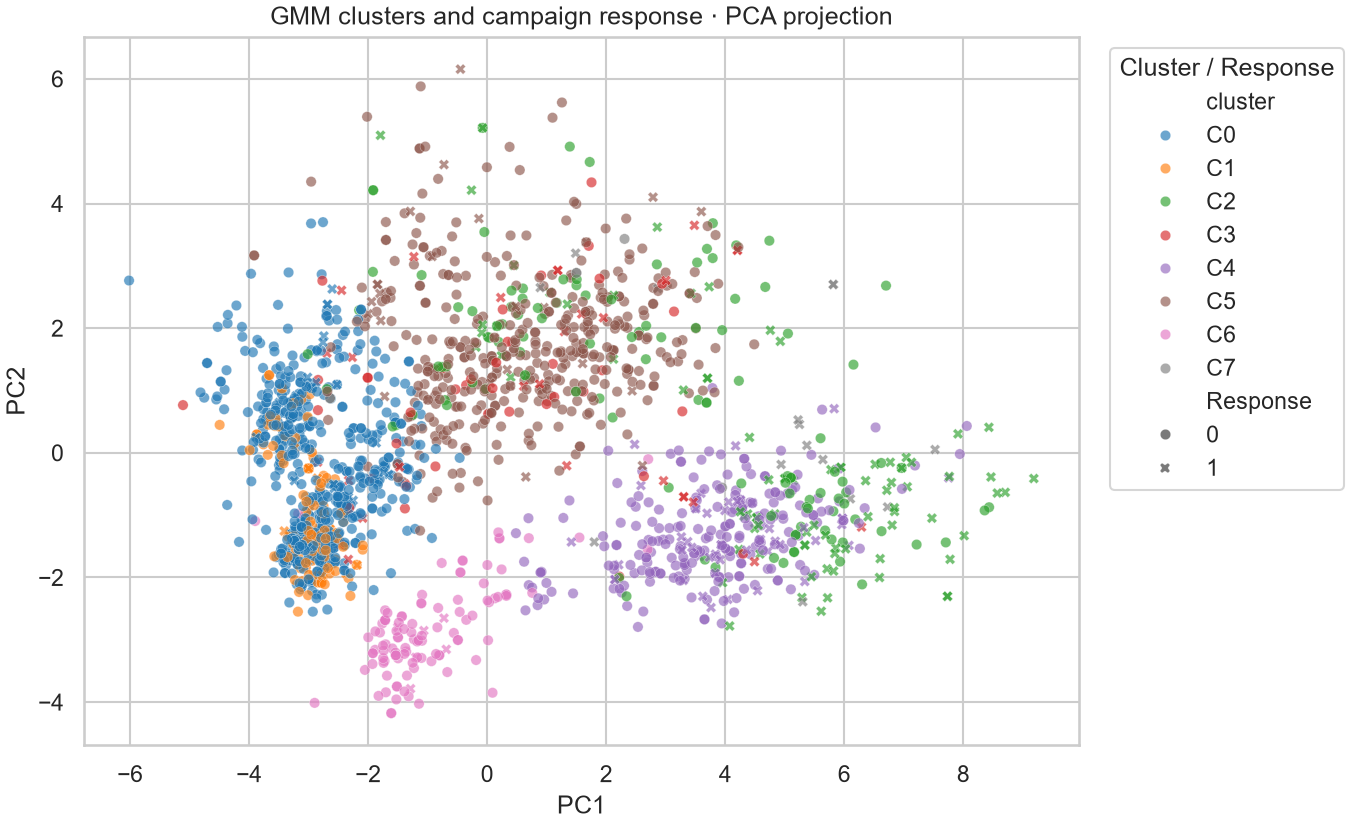

In [4]:
plotted = visual.assign(cluster=visual["cluster"].map(lambda label: f"C{label}"))
hue_order = [f"C{label}" for label in sorted(visual["cluster"].unique())]
palette = dict(zip(hue_order, sns.color_palette("tab10", len(hue_order))))
fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
sns.scatterplot(
    data=plotted, x="PC1", y="PC2", hue="cluster", hue_order=hue_order,
    style="Response", style_order=[0, 1], markers={0: "o", 1: "X"},
    palette=palette, s=25, alpha=0.65, linewidth=0.2, ax=ax,
)
ax.set(title="GMM clusters and campaign response · PCA projection")
ax.legend(title="Cluster / Response", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.savefig(figures / "gmm_clusters_pca.png", dpi=config.FIGURE_DPI)
plt.show()
plt.close(fig)

## Nhận xét trên development

GMM 8 thành phần có BIC thấp nhất trong dải 2–8 đã thử. Số thành phần được chọn nằm ở biên trên của dải thử. Silhouette của mô hình này là 0,109, trong khi ứng viên 2 thành phần đạt 0,262. BIC đánh giá độ khớp mô hình phân phối có phạt độ phức tạp. Silhouette đánh giá độ gắn kết và tách biệt theo khoảng cách Euclidean.

C0 gồm 571 khách hàng, có trung vị tổng chi tiêu 65 và tỷ lệ hưởng ứng 6,3%. C2 gồm 199 khách hàng, có trung vị thu nhập 76.995, tổng chi tiêu 1.381 và tỷ lệ hưởng ứng 42,2%, cao gấp 2,83 lần mức chung 14,9%. C5 có mức chi tiêu trung vị 704 nhưng tỷ lệ hưởng ứng 6,4%, cho thấy mức chi tiêu và khả năng hưởng ứng chiến dịch còn khác nhau giữa các hồ sơ.

C7 có tỷ lệ hưởng ứng 71,4% với 15 người hưởng ứng trên 21 khách hàng. Quy mô cụm này chiếm 1,2% development, nên tỷ lệ mô tả cần được đọc cùng số mẫu. Các kết quả thể hiện mối liên hệ trên tập khảo sát.

## Ghép với kết quả K-Means của ChinhBui

Đối chiếu Silhouette trên cùng tập development và cùng ma trận 37 đặc trưng sau tiền xử lý. Bảng hồ sơ cụm dùng để so sánh quy mô, mức chi tiêu và tỷ lệ hưởng ứng giữa các phân đoạn. Số hiệu cụm là định danh riêng của từng lần fit. Khi ghép kết quả, đối chiếu hồ sơ và khách hàng trong cụm để xác định các nhóm tương ứng.